In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/penguins_cleaned.csv")

df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.10,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.50,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.30,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,44.45,17.3,197.0,4050.0,MALE
4,Adelie,Torgersen,36.70,19.3,193.0,3450.0,FEMALE


In [2]:
# Dataset shape
print("Dataset Shape:", df.shape)

# Column information
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
df.describe()

Dataset Shape: (344, 7)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     344 non-null    float64
 3   bill_depth_mm      344 non-null    float64
 4   flipper_length_mm  344 non-null    float64
 5   body_mass_g        344 non-null    float64
 6   sex                344 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB

Missing Values:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

Statistical Summary:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,344.000000,344.000000,344.000000,344.000000
mean,43.925000,17.152035,200.892442,4200.872093
std,5.443792,1.969060,14.023826,799.696532
min,32.100000,13.100000,172.000000,2700.000000
25%,39.275000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


# End-to-End Data Science Case Study: Palmer Penguins Dataset

## 1. Problem Statement

The objective of this project is to analyze penguin measurements and develop a Machine Learning model to predict penguin species.

The dataset contains physical measurements such as bill length, bill depth, flipper length, and body mass, along with categorical information such as island and sex.

This project covers data preparation, exploratory data analysis (EDA), data visualization, machine learning model development, model evaluation, and conclusions.

### Objective
- Understand the Palmer Penguins dataset.
- Clean and prepare the data.
- Identify meaningful patterns through EDA.
- Build a classification model to predict penguin species.
- Evaluate model performance and summarize findings.

In [3]:
# Species distribution
print("Species Distribution:")
print(df["species"].value_counts())

# Average measurements by species
print("\nAverage Measurements by Species:")
print(df.groupby("species")[
    ["bill_length_mm", "bill_depth_mm",
     "flipper_length_mm", "body_mass_g"]
].mean())

Species Distribution:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Average Measurements by Species:
           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie          38.828618      18.339474         190.000000  3702.960526
Chinstrap       48.833824      18.420588         195.823529  3733.088235
Gentoo          47.480242      15.000806         217.024194  5067.741935


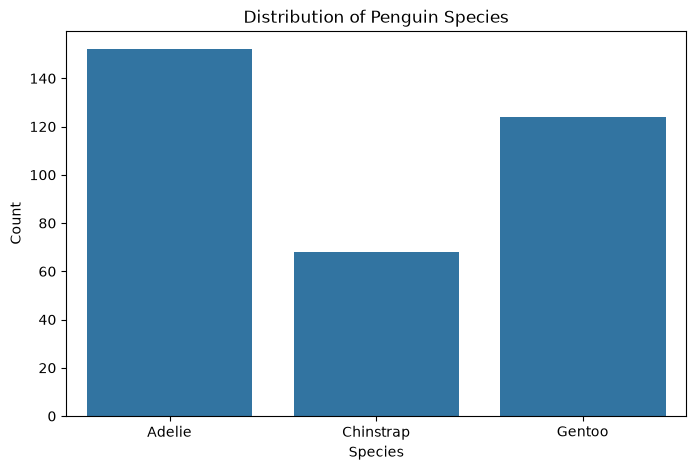

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Species distribution chart
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="species")
plt.title("Distribution of Penguin Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

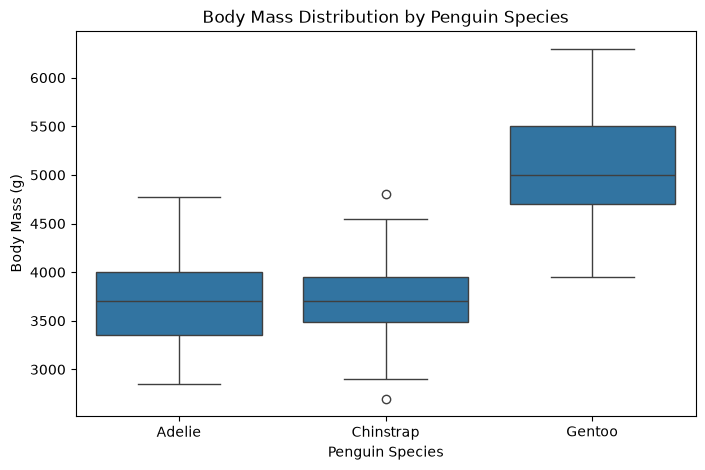

In [5]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="species", y="body_mass_g")

plt.title("Body Mass Distribution by Penguin Species")
plt.xlabel("Penguin Species")
plt.ylabel("Body Mass (g)")

plt.show()

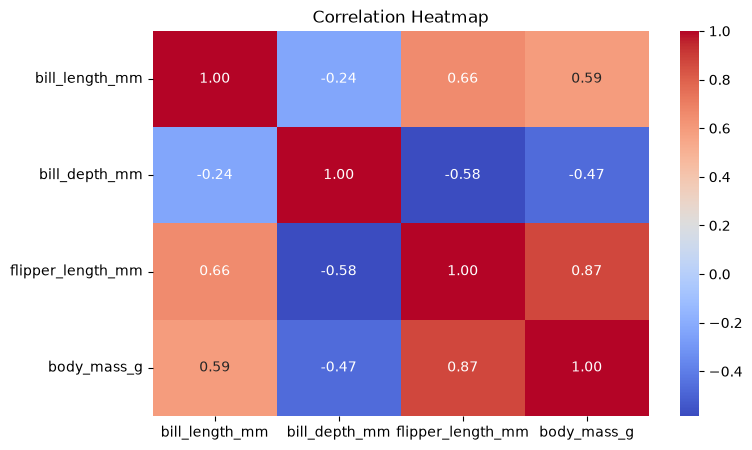

In [ ]:
plt.figure(figsize=(8, 5))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

## 2. Exploratory Data Analysis – Key Insights

1. Adelie is the most common penguin species, followed by Gentoo and Chinstrap.
2. Gentoo penguins have a higher body mass compared to Adelie and Chinstrap penguins.
3. Flipper length and body mass show a strong positive correlation of 0.87.
4. Bill length and flipper length have a positive correlation of 0.66.
5. Bill depth and flipper length show a negative correlation of -0.58.

These findings indicate that physical measurements contain useful information for predicting penguin species.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Select features and target
X = df[
    ["bill_length_mm", "bill_depth_mm",
     "flipper_length_mm", "body_mass_g"]
]

y = df["species"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Model 1: Logistic Regression
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

# Model 2: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# Compare accuracy
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_pred))

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

Logistic Regression Accuracy: 1.0
Random Forest Accuracy: 0.9855072463768116


LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69


RANDOM FOREST REPORT
              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       0.93      1.00      0.97        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.98      0.99      0.98        69
weighted avg       0.99      0.99      0.99        69



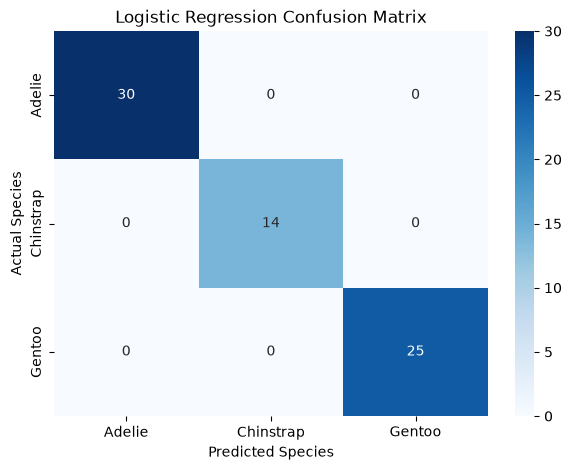

In [8]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test, lr_pred))

print("\nRANDOM FOREST REPORT")
print(classification_report(y_test, rf_pred))

# Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    confusion_matrix(y_test, lr_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=lr_model.classes_,
    yticklabels=lr_model.classes_
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

## 3. Model Development and Evaluation

Two classification algorithms were implemented:

1. Logistic Regression
2. Random Forest Classifier

The dataset was divided into 80% training data and 20% testing data.

### Model Performance

| Model | Accuracy |
|---|---:|
| Logistic Regression | 100% |
| Random Forest | 98.55% |

Logistic Regression achieved the highest accuracy on the selected test split.

## 4. Conclusion

This end-to-end data science project successfully analyzed the Palmer Penguins dataset and developed machine learning models to predict penguin species.

Data preparation ensured that missing values were handled. Exploratory Data Analysis identified important patterns and relationships between physical measurements.

Two machine learning models were trained and evaluated. Logistic Regression achieved 100% accuracy, while Random Forest achieved 98.55% accuracy on the test dataset.

The results demonstrate that penguin physical measurements can be useful features for species classification.

### Future Improvements

- Test additional classification algorithms.
- Perform cross-validation.
- Tune model hyperparameters.
- Evaluate performance on unseen datasets.

## 5. Final Outcome

The project successfully demonstrates the complete data science workflow, from data preparation and visualization to machine learning and model evaluation.